# 05. LLM을 Node에 연결하기
## 학습 목표
- `ChatOpenAI` 단독 호출과 Graph 내부 호출을 비교한다.
- 질문과 응답을 State에 보관한다.

**준비:** `OPENAI_API_KEY`가 필요하다. 기본 모델은 `gpt-4o-mini`이다. 각 실습은 API 요청을 한 번 수행하므로 비용이 발생할 수 있다.

## 핵심 개념·실행 전 예측
LLM은 입력 메시지를 받아 답을 만든다. LangGraph는 LLM 자체가 아니라 그 호출 순서와 State 흐름을 구성한다. 같은 질문을 두 방식으로 호출하면 응답 문구가 반드시 완전히 같을까?

In [1]:
from langchain_core.globals import set_llm_cache, get_llm_cache
from langchain_core.caches import InMemoryCache
from common.ai_model import get_llm_model

# 동일한 프롬프트+모델 파라미터로 호출하면 API를 다시 부르지 않고
# 캐시된 응답을 즉시 반환한다. 커널을 재시작하면 캐시는 사라진다.
set_llm_cache(InMemoryCache())

llm_options = {"model": "gpt-4o-mini", "temperature": 0}

llm = get_llm_model(**llm_options)
print("사용 모델:", llm_options["model"])
print("캐시 종류:", type(get_llm_cache()).__name__)


사용 모델: gpt-4o-mini
캐시 종류: InMemoryCache


In [2]:
import time
start = time.perf_counter()
question = "LangGraph의 State를 한 문장으로 설명해줘."
direct_answer = llm.invoke(question)
llm_call_sec = time.perf_counter() - start
print(f"1차 호출(API)  : {llm_call_sec:.3f}초")
print("LangChain 단독 응답:", direct_answer.content)


1차 호출(API)  : 2.025초
LangChain 단독 응답: LangGraph의 **State**는 **그래프의 각 노드가 공유하고 갱신하는 실행 중 데이터의 상태 저장소**입니다.


## 인메모리 캐시 동작 확인
같은 질문을 두 번 호출해 첫 번째(API 호출)와 두 번째(캐시 히트)의 응답 시간을 비교한다.

In [ ]:
import time

start = time.perf_counter()
cached_once = llm.invoke(question)
first_call_sec = time.perf_counter() - start

start = time.perf_counter()
cached_twice = llm.invoke(question)  # 동일 질문 -> 캐시 히트
second_call_sec = time.perf_counter() - start

print(f"1차 호출(API)  : {first_call_sec:.3f}초")
print(f"2차 호출(캐시) : {second_call_sec:.3f}초")


# 응답 동일 여부 확인
print("응답 동일 여부:", cached_once.content == cached_twice.content)

# 시간 비용 테스트
assert first_call_sec < llm_call_sec
assert second_call_sec < llm_call_sec

1차 호출(API)  : 0.003초
2차 호출(캐시) : 0.001초
응답 동일 여부: True


## LLM을 Graph에 연결하기

In [4]:
from pydantic import BaseModel
from langgraph.graph import START, END, StateGraph

class QAState(BaseModel):
    question: str
    answer: str

def llm_node(state: QAState) -> dict:
    # Node는 입력 State의 질문을 사용하고 응답만 업데이트한다.
    response = llm.invoke(state.question)
    return {"answer": response.content}

builder = StateGraph(QAState)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", END)
graph = builder.compile()

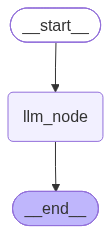

In [5]:
from IPython.display import Image, display

# PNG 생성에 네트워크 등이 필요하면 Mermaid 텍스트로 대체한다.
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    print("PNG 시각화 불가:", type(exc).__name__)
    print(graph.get_graph().draw_mermaid())

In [6]:
result = graph.invoke({"question": question, "answer": ""})
print("질문:", result["question"])
print("Graph 응답:", result["answer"])
assert result["question"] == question and bool(result["answer"])

질문: LangGraph의 State를 한 문장으로 설명해줘.
Graph 응답: LangGraph의 State는 언어 모델의 현재 상태를 나타내며, 입력된 텍스트와 그에 대한 처리 결과를 기반으로 다음 단계를 결정하는 데 사용됩니다.


`temperature=0`이어도 API 호출마다 문구가 같다고 보장되지는 않는다. 비교할 대상은 문자열의 완전 일치보다 **호출 경로와 State 저장 위치**이다.

## 작은 수정 실습
질문을 "Node와 Edge의 차이를 한 문장으로 설명해줘"로 바꾸어 Graph를 한 번만 더 실행한다. 어떤 필드가 입력이고 어떤 필드가 업데이트인지 표시한다.

## 이해 확인
1. `llm_node`가 `question`을 반환하지 않아도 최종 State에 남는 이유는 무엇인가?  
   **해설:** 반환된 `answer`만 덮어쓰고 나머지 State는 유지된다.
2. LangGraph가 답변을 생성하는 모델인가?  
   **해설:** 아니다. 답변은 `ChatOpenAI`가 생성하고 Graph는 실행과 State 이동을 관리한다.

**핵심 정리:** LLM을 Node 내부에 배치하면 모델 응답을 Graph State의 일부로 저장하고 다음 단계로 전달할 수 있다.